*Mathematical Foundations of Robotics · Chapter 1 — Introduction, Joints and Degrees of Freedom*

# 1.2 A Tour of Real Robots

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kushagrathisside/Robotics-Guide/blob/main/MFoR/01-introduction-and-degrees-of-freedom/1.2-a-tour-of-real-robots.ipynb)

Definitions become convincing when they can be *measured*. This notebook takes seven robots from MuJoCo Menagerie — the
Dynamixel 2R, the Universal Robots UR5e, the Franka Emika Panda, the KUKA iiwa 14, the Rethink Sawyer and Baxter, and the ROBOTIS
OP3 humanoid — and reads their joints directly from the simulator's model: type, axis, range, and the geometric
relation between consecutive axes. From these numbers we name each robot, find out which have a *spherical wrist*,
explain why the simulator's counts `nq`, `nv` and `nu` differ, and see how a humanoid is a kinematic *tree*.

| | |
|:--|:--|
| **Primary reading** | Craig, 3rd ed., Ch. 1 (Introduction); the robots of the tour appear again in the worked examples of Ch. 3 and Ch. 4 |
| **Parallel reading** | Siciliano et al., Ch. 1 (classification, wrist and arm structures) · Spong, Hutchinson & Vidyasagar, Ch. 1 (common kinematic arrangements) · Lynch & Park, Ch. 2 (§2.1–2.2) |
| **Lectures** | [Prof. G. C. Nandi — Lecture 1 — Introduction](https://www.youtube.com/watch?v=7_EEBOgdGM8) · [Prof. G. C. Nandi — Lecture 3 — Simple concepts of forward and inverse kinematics](https://www.youtube.com/watch?v=2ww-3c08BIs) |
| **Prerequisites** | [1.1 Robots, Links and Joints](1.1-robots-links-and-joints.ipynb) |
| **Study time** | about 2½ hours, including the exercises |

## Learning objectives

After working through this notebook you should be able to:

1. extract the joint type, world-frame axis, anchor point and range of every joint of a MuJoCo model;
2. name a robot by its joint sequence and classify its arm and wrist from the **relations between joint axes**;
3. compute the **distance and angle between consecutive joint axes** — the link length and twist of Chapter 3 — and read them off real robots;
4. test numerically whether three joint axes are concurrent (a *spherical* shoulder or wrist) for all configurations;
5. explain the difference between `nq`, `nv`, `nu` and the true number of degrees of freedom, using the Panda gripper and the OP3 floating base as examples;
6. describe the OP3 humanoid as a kinematic tree of serial limbs and identify the joint structure of its leg.

## Contents

1. [The gallery](#1.-The-gallery)
2. [The joint census](#2.-The-joint-census)
3. [Joint axes: link length and twist](#3.-Joint-axes:-link-length-and-twist)
4. [Spherical shoulders and wrists](#4.-Spherical-shoulders-and-wrists)
5. [Counting freedoms: nq, nv, nu and mobility](#5.-Counting-freedoms:-nq,-nv,-nu-and-mobility)
6. [Joint limits](#6.-Joint-limits)
7. [A humanoid is a tree](#7.-A-humanoid-is-a-tree)
8. [Worked examples](#8.-Worked-examples)
9. [Summary, common mistakes and exercises](#9.-Summary)

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Makes the shared `rgkit` package importable, both locally and on Google Colab.
import sys, pathlib, subprocess
if "google.colab" in sys.modules:                                   # Colab
    if not pathlib.Path("Robotics-Guide").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/kushagrathisside/Robotics-Guide.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mujoco", "mediapy"], check=True)
    sys.path.insert(0, "Robotics-Guide")
else:                                                               # local Jupyter
    root = pathlib.Path.cwd().resolve()
    while not (root / "rgkit").is_dir() and root != root.parent:
        root = root.parent
    sys.path.insert(0, str(root))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown
import ipywidgets as widgets

from rgkit import setup_notebook, interact
from rgkit.plotting import (new_axes3d, draw_frame, draw_vector, draw_point, draw_box,
                            draw_frame_2d, draw_vector_2d, matrix_to_latex, AXIS_COLORS)
from rgkit.animation import animate, filmstrip

setup_notebook()
deg = np.deg2rad          # degrees -> radians

from rgkit import mujoco_utils as mju, robots, joint_census as jc, mechanisms as mech
import mujoco

ROBOTS = ["2r", "ur5e", "panda", "iiwa14", "sawyer", "baxter", "op3"]
models = {}
for name in ROBOTS:
    models[name] = robots.load_robot(name, scene="light")        # the manufacturer's model in this repository's light scene
    print(robots.describe(name))

Dynamixel 2R arm — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/dynamixel_2r) (Marc Duclusaud & Grégoire Passault; licence: MIT)


Universal Robots UR5e — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/universal_robots_ur5e) (Universal Robots; licence: BSD-3-Clause)


Franka Emika Panda — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/franka_emika_panda) (Franka Emika; licence: Apache-2.0)
KUKA LBR iiwa 14 — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/kuka_iiwa_14) (KUKA; licence: see model LICENSE)


Rethink Robotics Sawyer — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/rethink_robotics_sawyer) (Rethink Robotics; licence: see model LICENSE)


Rethink Robotics Baxter (dual-arm) — model from [robosuite](https://github.com/ARISE-Initiative/robosuite/tree/v1.5.2/robosuite/models/assets/robots/baxter) (Rethink Robotics; licence: MIT (robosuite model files); original design by Rethink Robotics)


ROBOTIS OP3 humanoid — model from [MuJoCo Menagerie](https://github.com/google-deepmind/mujoco_menagerie/tree/98a70c56/robotis_op3) (ROBOTIS; licence: see model LICENSE)


## 1. The gallery

The seven models below are rendered in their default configuration (the manufacturer's `home` keyframe where one
exists). Each numbered disc is placed at the **anchor** of a joint — the point on the joint axis that MuJoCo uses as the
origin of the joint — read from the model and projected onto the image; red marks revolute joints and orange marks
prismatic ones. The numbers are the order in which the joints appear in the model, which for a serial arm is the order from the base to the tip.

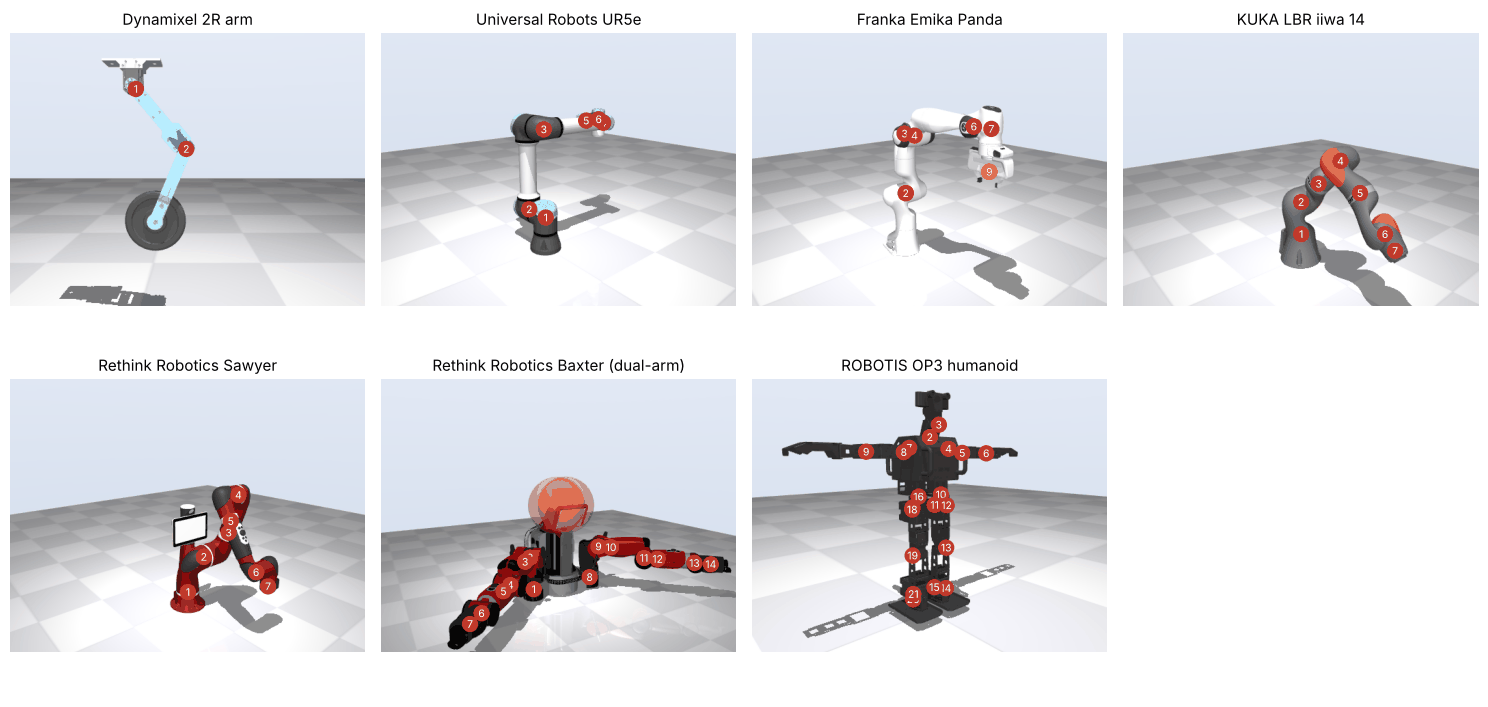

In [2]:
cams = {"2r": dict(azimuth=90, elevation=-5, distance=0.75, lookat=(0.12, 0, 0.36)),
        "ur5e": dict(azimuth=140, elevation=-15, distance=1.45, lookat=(0.1, 0, 0.42)),
        "panda": dict(azimuth=140, elevation=-15, distance=1.55, lookat=(0.2, 0, 0.5)),
        "iiwa14": dict(azimuth=140, elevation=-15, distance=1.85, lookat=(0, 0, 0.55)),
        "sawyer": dict(azimuth=140, elevation=-15, distance=1.85, lookat=(0, 0, 0.55)),
        "baxter": dict(azimuth=150, elevation=-10, distance=2.6, lookat=(0, 0, 0.6)),
        "op3": dict(azimuth=140, elevation=-10, distance=0.8, lookat=(0, 0, 0.25))}
m2r, d2r = models["2r"]; d2r.qpos[:] = [0.7, -1.1]; mujoco.mj_forward(m2r, d2r)          # a bent pose; q = 0 hangs straight down

fig, axs = plt.subplots(2, 4, figsize=(15, 7.4))
axs.ravel()[-1].set_axis_off()
for ax, name in zip(axs.ravel(), ROBOTS):
    m, d = models[name]
    img = mju.render(m, d, camera=cams[name], width=520, height=400)
    ax.imshow(img); ax.set_axis_off(); ax.grid(False)
    rows = jc.joint_table(m, d)
    uv = jc.project_points(m, cams[name], [r["anchor"] for r in rows], 520, 400)
    for k, ((u, v), r) in enumerate(zip(uv, rows), 1):
        if r["type"] == "free" or np.isnan(u): continue
        ax.text(u, v, str(k), color="white", fontsize=7.5, ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.18", fc="#c0392b" if r["symbol"] == "R" else "#e67e22", ec="none"))
    ax.set_title(robots.ROBOTS[name]["title"], fontsize=11)
plt.tight_layout(); plt.show()

## 2. The joint census

The function `joint_census.joint_table` turns the simulator's arrays (`jnt_type`, `jnt_range`, `xaxis`, `xanchor`, …)
into one record per joint, evaluated at the current configuration. For a serial arm the joint axes depend on the
joint angles of the joints *before* them; we evaluate the table at the home configuration. As an example, here is the
UR5e — the same six-joint arm we met in Notebook 1.1 — as a table.

In [3]:
def joint_markdown(name):
    m, d = models[name]
    lines = ["| # | name | type | axis in the world frame | range (degrees) | body |", "|:-:|:--|:-:|:--|:--|:--|"]
    for k, r in enumerate(jc.joint_table(m, d), 1):
        rng_ = "unlimited" if r["range"] is None else f"{np.degrees(r['range'][0]):.0f} … {np.degrees(r['range'][1]):.0f}" if r["symbol"] == "R" else f"{r['range'][0]:.3f} … {r['range'][1]:.3f} m"
        ax_ = "—" if r["type"] in ("free", "ball") else "(" + ", ".join(f"{v:+.2f}" for v in r["axis"]) + ")"
        lines.append(f"| {k} | `{r['name']}` | {r['symbol']} ({r['type']}) | {ax_} | {rng_} | `{r['body']}` |")
    return "\n".join(lines)

display(Markdown(joint_markdown("ur5e")))
m, d = models["ur5e"]
types = [r["symbol"] for r in jc.joint_table(m, d)]
print("\nUR5e joint sequence read from the model:", "".join(types), "-> a", f"{types.count('R')}R arm")

| # | name | type | axis in the world frame | range (degrees) | body |
|:-:|:--|:-:|:--|:--|:--|
| 1 | `shoulder_pan_joint` | R (hinge) | (+0.00, +0.00, +1.00) | -360 … 360 | `shoulder_link` |
| 2 | `shoulder_lift_joint` | R (hinge) | (-1.00, +0.00, +0.00) | -360 … 360 | `upper_arm_link` |
| 3 | `elbow_joint` | R (hinge) | (-1.00, +0.00, +0.00) | -180 … 180 | `forearm_link` |
| 4 | `wrist_1_joint` | R (hinge) | (-1.00, +0.00, +0.00) | -360 … 360 | `wrist_1_link` |
| 5 | `wrist_2_joint` | R (hinge) | (+0.00, +1.00, +0.00) | -360 … 360 | `wrist_2_link` |
| 6 | `wrist_3_joint` | R (hinge) | (+0.00, +0.00, -1.00) | -360 … 360 | `wrist_3_link` |


UR5e joint sequence read from the model: RRRRRR -> a 6R arm


Every row is a *hinge*: the UR5e is a **6R** arm. Look at the *axis* column: joint 1 turns about the vertical, joints
2, 3 and 4 about one common horizontal direction (they are **parallel**), joint 5 about the other horizontal direction
and joint 6 about the tool axis (pointing downwards at the home pose). That pattern — one vertical axis, three parallel
horizontal axes, then two axes perpendicular to each other and to the third — is the signature of the UR family and has
consequences for inverse kinematics (Chapter 4).

The same function works for any model. The next cell prints, for every robot of the tour, the **kinematic chain** from
the world to its end body — the joint sequence — using `chain_joints`.

In [4]:
tips = {"2r": "second_segment", "ur5e": "wrist_3_link", "panda": "link7", "iiwa14": "link7", "sawyer": "right_l6", "baxter": "right_wrist"}
chains = {}
lines = ["| robot | joints in the chain to the tip | sequence | arm class from the first axes |", "|:--|:--|:-:|:--|"]
for name, tip in tips.items():
    m, d = models[name]
    chains[name] = jc.chain_joints(m, d, tip)
    seq = "".join(r["symbol"] for r in chains[name])
    first = chains[name]
    a12 = np.degrees(jc.axis_relation(first[0]["anchor"], first[0]["axis"], first[1]["anchor"], first[1]["axis"])[1])
    lines.append(f"| {robots.ROBOTS[name]['title']} | {len(chains[name])} | **{seq}** | angle between axes 1 and 2: {a12:.0f}° |")
display(Markdown("\n".join(lines)))

| robot | joints in the chain to the tip | sequence | arm class from the first axes |
|:--|:--|:-:|:--|
| Dynamixel 2R arm | 2 | **RR** | angle between axes 1 and 2: 0° |
| Universal Robots UR5e | 6 | **RRRRRR** | angle between axes 1 and 2: 90° |
| Franka Emika Panda | 7 | **RRRRRRR** | angle between axes 1 and 2: 90° |
| KUKA LBR iiwa 14 | 7 | **RRRRRRR** | angle between axes 1 and 2: 90° |
| Rethink Robotics Sawyer | 7 | **RRRRRRR** | angle between axes 1 and 2: 90° |
| Rethink Robotics Baxter (dual-arm) | 7 | **RRRRRRR** | angle between axes 1 and 2: 90° |

Five of the seven robots are serial chains of revolute joints: the **2R** (planar), the **6R** UR5e and the **7R** Panda,
iiwa and Sawyer; Baxter consists of two 7R arms on one torso (a tree with two serial limbs; the table follows its right arm). In all of them axes 1 and 2 meet at $90^\circ$ except in the planar 2R, where they are parallel (a
planar arm has all axes parallel). The humanoid is treated in Section 7. The sequence alone does not tell the whole
story, though; the *geometry between the axes* does.

## 3. Joint axes: link length and twist

Two consecutive joint axes in a robot are two lines in space. Two numbers describe how they are related:

* the **distance** between them along their common perpendicular — the **link length** $a$ — and
* the **angle** between them, measured in a plane perpendicular to that common perpendicular — the **link twist** $\alpha$.

Because both axes are fixed in the same link, $a$ and $\alpha$ are *constants of the link*: they do not change when the robot
moves, which is why a robot can be described by a table of constants, the **Denavit–Hartenberg parameters** of Chapter 3. For
two skew lines through points $\mathbf p_1,\mathbf p_2$ with unit directions $\hat{\mathbf u}_1,\hat{\mathbf u}_2$,

$$
a = \frac{\lvert (\mathbf p_2-\mathbf p_1)\cdot(\hat{\mathbf u}_1\times\hat{\mathbf u}_2)\rvert}{\lVert \hat{\mathbf u}_1\times\hat{\mathbf u}_2\rVert},
\qquad
\alpha = \arccos\lvert \hat{\mathbf u}_1\cdot\hat{\mathbf u}_2\rvert ,
$$

and for parallel lines $a$ is the perpendicular distance between them. The function `joint_census.axis_relation`
implements this, and we can prove the claim "constants of the link" numerically: compute $a$ and $\alpha$ for random
configurations and observe that they do not change.

In [5]:
rng = np.random.default_rng(7)
def random_q(m):
    q = m.qpos0.copy()
    for j in range(m.njnt):
        if m.jnt_type[j] in (2, 3):
            lo, hi = m.jnt_range[j] if m.jnt_limited[j] else (-np.pi, np.pi)
            q[m.jnt_qposadr[j]] = rng.uniform(lo, hi)
    return q

def link_table(name):
    """(a, alpha) between consecutive joint axes of the serial chain to the tip, at the current configuration."""
    m, d = models[name]
    rows = jc.chain_joints(m, d, tips[name])
    return [jc.axis_relation(a["anchor"], a["axis"], b["anchor"], b["axis"]) for a, b in zip(rows[:-1], rows[1:])]

# Do a and alpha depend on the configuration?  Compare 25 random configurations of the UR5e.
m, d = models["ur5e"]
tabs = []
for _ in range(25):
    d.qpos[:] = random_q(m); mujoco.mj_forward(m, d); tabs.append(np.array(link_table("ur5e")))
tabs = np.array(tabs)
print("largest spread of (a, alpha) over 25 random UR5e configurations:", np.ptp(tabs, axis=0).max().round(12))
assert np.ptp(tabs, axis=0).max() < 1e-12
d.qpos[:] = m.key_qpos[0]; mujoco.mj_forward(m, d)

largest spread of (a, alpha) over 25 random UR5e configurations: 0.0


In [6]:
def link_markdown(name):
    m, d = models[name]
    rows = chains[name]
    lines = ["| between | $a$ (m) | $\\alpha$ | relation |", "|:--|:-:|:-:|:--|"]
    for (a, b), (dist, ang) in zip(zip(rows[:-1], rows[1:]), link_table(name)):
        lines.append(f"| `{a['name']}` → `{b['name']}` | {dist:.4f} | {np.degrees(ang):.0f}° | {jc.axis_kind(dist, ang)} |")
    return "\n".join(lines)

for name in ["ur5e", "panda", "iiwa14"]:
    m, d = models[name]; mujoco.mj_forward(m, d)
    print(f"\n{robots.ROBOTS[name]['title']}")
    display(Markdown(link_markdown(name)))


Universal Robots UR5e


| between | $a$ (m) | $\alpha$ | relation |
|:--|:-:|:-:|:--|
| `shoulder_pan_joint` → `shoulder_lift_joint` | 0.0000 | 90° | perpendicular, intersecting |
| `shoulder_lift_joint` → `elbow_joint` | 0.4250 | 0° | parallel |
| `elbow_joint` → `wrist_1_joint` | 0.3920 | 0° | parallel |
| `wrist_1_joint` → `wrist_2_joint` | 0.0000 | 90° | perpendicular, intersecting |
| `wrist_2_joint` → `wrist_3_joint` | 0.0000 | 90° | perpendicular, intersecting |


Franka Emika Panda


| between | $a$ (m) | $\alpha$ | relation |
|:--|:-:|:-:|:--|
| `joint1` → `joint2` | 0.0000 | 90° | perpendicular, intersecting |
| `joint2` → `joint3` | 0.0000 | 90° | perpendicular, intersecting |
| `joint3` → `joint4` | 0.0825 | 90° | perpendicular, offset |
| `joint4` → `joint5` | 0.0825 | 90° | perpendicular, offset |
| `joint5` → `joint6` | 0.0000 | 90° | perpendicular, intersecting |
| `joint6` → `joint7` | 0.0880 | 90° | perpendicular, offset |


KUKA LBR iiwa 14


| between | $a$ (m) | $\alpha$ | relation |
|:--|:-:|:-:|:--|
| `joint1` → `joint2` | 0.0000 | 90° | perpendicular, intersecting |
| `joint2` → `joint3` | 0.0000 | 90° | perpendicular, intersecting |
| `joint3` → `joint4` | 0.0000 | 90° | perpendicular, intersecting |
| `joint4` → `joint5` | 0.0000 | 90° | perpendicular, intersecting |
| `joint5` → `joint6` | 0.0000 | 90° | perpendicular, intersecting |
| `joint6` → `joint7` | 0.0000 | 90° | perpendicular, intersecting |

Three different philosophies of arm design are visible in the tables.

* **UR5e**: the two long links have $a = 0.425$ m and $a = 0.392$ m between **parallel** axes (shoulder, elbow, first
  wrist joint); all other consecutive pairs meet at right angles with $a=0$. (Universal Robots publishes
  $0.425$ m and $0.3922$ m for these two links; the Menagerie model rounds the second to 0.392 m.)
* **Franka Panda**: all twists are $90^\circ$ and three link lengths are non-zero — $0.0825$ m twice and $0.088$ m —
  the small *offsets* that make the arm compact and give it its characteristic elbow shape. These agree with the
  link lengths in Franka's published Denavit–Hartenberg table.
* **KUKA iiwa 14**: **every** pair of consecutive axes meets at right angles *and intersects* ($a = 0$ throughout):
  the arm is a chain of seven revolute joints whose axes all pass through the preceding joint's axis. That
  property will give the iiwa a *spherical* shoulder and wrist in Section 4.

The Sawyer's table (try `link_markdown("sawyer")`) has a single non-zero length, $0.081$ m, between its first two axes.

## 4. Spherical shoulders and wrists

A joint triple is **concurrent** (a *spherical* arrangement) if its three axes pass through one point **for every**
configuration. A spherical wrist is the classical example; a spherical shoulder is the same property of the first three
joints. We test it numerically. For $k$ lines $\{\mathbf p_i + t\,\hat{\mathbf u}_i\}$ the point closest to all of them (in the sense of least squares) is the solution of

$$
\Big(\sum_i P_i\Big)\mathbf x = \sum_i P_i\,\mathbf p_i,\qquad P_i = I - \hat{\mathbf u}_i\hat{\mathbf u}_i^{\mathsf T},
$$

where $P_i$ projects onto the plane perpendicular to line $i$, and the **miss distance** is the largest distance from that
point to any of the lines. If the miss distance is zero for *many random configurations*, the triple is concurrent.
(One configuration is not enough: three lines can meet by accident in a special pose.)

In [7]:
def closest_point_and_miss(lines):
    """Least-squares point nearest to all lines (p, u) and the largest distance from it to a line."""
    A, b = np.zeros((3, 3)), np.zeros(3)
    for p, u in lines:
        P = np.eye(3) - np.outer(u, u); A += P; b += P @ p
    x = np.linalg.solve(A, b)
    return x, max(np.linalg.norm((np.eye(3) - np.outer(u, u)) @ (x - p)) for p, u in lines)

def worst_miss(name, which, trials=40):
    m, d = models[name]; rows_ = None; worst = 0.0
    for _ in range(trials):
        d.qpos[:] = random_q(m); mujoco.mj_forward(m, d)
        rows_ = jc.chain_joints(m, d, tips[name])
        sel = rows_[:3] if which == "first" else rows_[-3:]
        worst = max(worst, closest_point_and_miss([(r["anchor"], r["axis"]) for r in sel])[1])
    d.qpos[:] = m.key_qpos[0] if m.nkey else m.qpos0; mujoco.mj_forward(m, d)
    return worst

lines = ["| robot | first three axes: worst miss (mm) | last three axes: worst miss (mm) | spherical shoulder | spherical wrist |", "|:--|:-:|:-:|:-:|:-:|"]
verdict = {}
for name in ["ur5e", "panda", "iiwa14", "sawyer", "baxter"]:
    f, l = worst_miss(name, "first") * 1000, worst_miss(name, "last") * 1000
    verdict[name] = (f < 1e-6, l < 1e-6)
    lines.append(f"| {robots.ROBOTS[name]['title']} | {f:.3f} | {l:.3f} | {'yes' if f < 1e-6 else 'no'} | {'yes' if l < 1e-6 else 'no'} |")
display(Markdown("\n".join(lines)))
assert verdict["iiwa14"] == (True, True) and verdict["ur5e"] == (False, False) and verdict["panda"] == (True, False)
print("Baxter (right arm): spherical shoulder, spherical wrist =", verdict["baxter"])

| robot | first three axes: worst miss (mm) | last three axes: worst miss (mm) | spherical shoulder | spherical wrist |
|:--|:-:|:-:|:-:|:-:|
| Universal Robots UR5e | 283.268 | 50.000 | no | no |
| Franka Emika Panda | 0.000 | 58.624 | yes | no |
| KUKA LBR iiwa 14 | 0.000 | 0.000 | yes | yes |
| Rethink Robotics Sawyer | 110.363 | 68.150 | no | no |
| Rethink Robotics Baxter (dual-arm) | 45.979 | 6.606 | no | no |

Baxter (right arm): spherical shoulder, spherical wrist = (np.False_, np.False_)


The test identifies the structure of each arm without any catalogue. Only the **iiwa 14** has both a spherical shoulder
and a spherical wrist; the **Panda** has a spherical shoulder but its last three axes miss each other by
the offset $0.088$ m; the **UR5e**, the **Sawyer** and Baxter's arm have neither. Why does it matter? A 6-joint arm whose last three axes meet at a
point has its **wrist centre** determined by the first three joints alone, so inverse kinematics splits into a
position problem and an orientation problem (*kinematic decoupling*, Chapter 4). The UR5e is nevertheless solvable in
closed form because of a different property — its three parallel axes — and the Panda needs numerical
or special-purpose methods.

The *kinematic skeleton* below makes the geometry visible. For each arm the polyline joins the joint anchors, and the
arrows are the joint axes, all read from the model at the home configuration. In the iiwa (c) the axes pass
through the shoulder and the wrist points; in the UR5e (a) three axes are parallel.

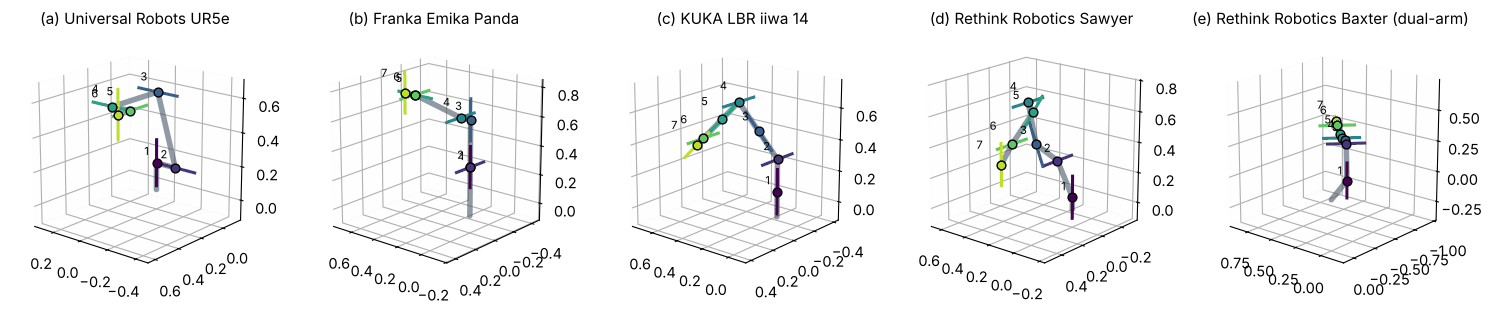

In [8]:
def skeleton(ax, name, scale=0.14, title=None):
    m, d = models[name]; mujoco.mj_forward(m, d)
    rows = chains[name]
    tip_body = d.xpos[mujoco.mj_name2id(m, mujoco.mjtObj.mjOBJ_BODY, tips[name])]
    P = np.array([[0, 0, 0]] + [r["anchor"] for r in rows] + [tip_body])
    ax.plot(*P.T, "-", color="#34495e", lw=4, alpha=0.55, solid_capstyle="round")
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(rows)))
    for k, (r, c) in enumerate(zip(rows, cmap), 1):
        a = r["axis"]
        ax.plot(*np.array([r["anchor"] - scale * a, r["anchor"] + scale * a]).T, "-", color=c, lw=2.2)
        ax.scatter(*r["anchor"], s=40, color=c, edgecolors="k", zorder=5)
        ax.text(*(r["anchor"] + 0.04 + 0.01 * k), str(k), fontsize=8)
    lo_, hi_ = P.min(0) - 0.12, P.max(0) + 0.12
    c_, r_ = (lo_ + hi_) / 2, (hi_ - lo_).max() / 2
    new_axes3d(ax, lim=tuple((c_[i] - r_, c_[i] + r_) for i in range(3)), title=title or robots.ROBOTS[name]["title"], elev=18, azim=130)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_zlabel("")

fig = plt.figure(figsize=(15, 3.8))
for k, (name, tag) in enumerate([("ur5e", "(a)"), ("panda", "(b)"), ("iiwa14", "(c)"), ("sawyer", "(d)"), ("baxter", "(e)")]):
    skeleton(fig.add_subplot(1, 5, k + 1, projection="3d"), name, title=f"{tag} {robots.ROBOTS[name]['title']}")
plt.tight_layout(); plt.show()

## 5. Counting freedoms: `nq`, `nv`, `nu` and mobility

MuJoCo reports four related numbers for a model, and a beginner is easily misled by them.

| Symbol | Meaning | Remark |
|:--|:--|:--|
| `nq` | length of the position vector `qpos` | a **ball** joint uses 4 numbers (a quaternion) and a **free** joint 7 (position + quaternion) |
| `nv` | length of the velocity vector `qvel` | one number per *degree of freedom* of the declared joints: hinge 1, slide 1, ball 3, free 6 |
| `nu` | number of actuators | what the controller can command; may be smaller or larger than `nv` |
| `neq` | number of equality constraints | loop closures and couplings; each *removes* freedoms |

The true **mobility** of the model is $n_v$ minus the rank of the equality-constraint Jacobian — Grübler's count carried
out by the simulator (Notebook 1.3). The table applies it to every robot.

In [9]:
lines = ["| robot | nq | nv | nu | neq | mobility = nv − rank | comment |", "|:--|:-:|:-:|:-:|:-:|:-:|:--|"]
comments = {"2r": "planar arm, 2 actuated joints",
            "ur5e": "6 joints, 6 actuators",
            "panda": "7 arm joints + 2 finger joints tied by an equality constraint; 7 + 1 actuators",
            "iiwa14": "7 joints, 7 actuators: redundant for a 6-D task",
            "sawyer": "7 joints, 7 actuators",
            "baxter": "two 7R arms on one torso: 14 joints, 14 actuators",
            "op3": "free base (7 numbers, 6 velocities) + 20 joints; only 20 actuated"}
mob = {}
for name in ROBOTS:
    m, d = models[name]
    nq, nv, nu, neq = jc.describe_dofs(m)
    mob[name] = jc.model_mobility(m, d)
    lines.append(f"| {robots.ROBOTS[name]['title']} | {nq} | {nv} | {nu} | {neq} | **{mob[name]}** | {comments[name]} |")
display(Markdown("\n".join(lines)))

| robot | nq | nv | nu | neq | mobility = nv − rank | comment |
|:--|:-:|:-:|:-:|:-:|:-:|:--|
| Dynamixel 2R arm | 2 | 2 | 2 | 0 | **2** | planar arm, 2 actuated joints |
| Universal Robots UR5e | 6 | 6 | 6 | 0 | **6** | 6 joints, 6 actuators |
| Franka Emika Panda | 9 | 9 | 8 | 1 | **8** | 7 arm joints + 2 finger joints tied by an equality constraint; 7 + 1 actuators |
| KUKA LBR iiwa 14 | 7 | 7 | 7 | 0 | **7** | 7 joints, 7 actuators: redundant for a 6-D task |
| Rethink Robotics Sawyer | 7 | 7 | 7 | 0 | **7** | 7 joints, 7 actuators |
| Rethink Robotics Baxter (dual-arm) | 14 | 14 | 14 | 0 | **14** | two 7R arms on one torso: 14 joints, 14 actuators |
| ROBOTIS OP3 humanoid | 27 | 26 | 20 | 0 | **26** | free base (7 numbers, 6 velocities) + 20 joints; only 20 actuated |

Three cases show the three ways `nq`, `nv` and `nu` can disagree.

1. **Panda: `nv` $\neq$ mobility.** The model declares two finger joints but couples them by an equality constraint
   (`finger_joint1 = finger_joint2`), so the hand has *one* freedom (open/close); the gripper has one actuator and the
   arm seven, so $n_u = 8 = $ mobility, even though $n_v = 9$.
2. **OP3: `nq` $\neq$ `nv`.** The humanoid is not attached to the ground; its base has a **free joint** with 7 position
   numbers (3 for position, 4 for a unit quaternion) but only 6 velocity numbers. The *implicit* quaternion
   representation of orientation carries one more number than the orientation has freedoms — a theme of Notebook 1.4.
3. **OP3: `nu` $<$ `nv`.** The 6 freedoms of the floating base have no actuator: a humanoid is **under-actuated** with respect to its base, and
   it moves its base only by pushing on the ground through contact. This distinguishes legged robots from fixed-base arms,
   where $n_u = n_v$.

The next cell reads these facts from the model instead of asserting them.

In [10]:
mP, dP = models["panda"]
print("Panda: joints declared:", [r["name"] for r in jc.joint_table(mP, dP)][-2:], "| equality constraints:", mP.neq,
      "->", "joint-coupling" if mP.eq_type[0] == mujoco.mjtEq.mjEQ_JOINT else "other")
print("Panda: actuators ->", [mujoco.mj_id2name(mP, mujoco.mjtObj.mjOBJ_ACTUATOR, i) for i in range(mP.nu)])
mO, dO = models["op3"]
print("OP3:   joint types:", sorted({r["type"] for r in jc.joint_table(mO, dO)}), "| nq - nv =", mO.nq - mO.nv,
      "| base free-joint qpos:", dO.qpos[:7].round(3), "(x, y, z, qw, qx, qy, qz)")
print("OP3:   actuated =", mO.nu, ", velocities =", mO.nv, "-> unactuated freedoms:", mO.nv - mO.nu)
assert mob["panda"] == 8 == mP.nu and mO.nq - mO.nv == 1 and mO.nv - mO.nu == 6

Panda: joints declared: ['finger_joint1', 'finger_joint2'] | equality constraints: 1 -> joint-coupling
Panda: actuators -> ['actuator1', 'actuator2', 'actuator3', 'actuator4', 'actuator5', 'actuator6', 'actuator7', 'actuator8']
OP3:   joint types: ['free', 'hinge'] | nq - nv = 1 | base free-joint qpos: [0.  0.  0.3 1.  0.  0.  0. ] (x, y, z, qw, qx, qy, qz)
OP3:   actuated = 20 , velocities = 26 -> unactuated freedoms: 6


## 6. Joint limits

Real joints cannot turn forever: cables, mechanical stops and sensors limit them. The bars show the allowed range
of every joint of the four serial arms, as read from `jnt_range`. The UR5e's joints span $\pm 360^\circ$ (except the elbow, $\pm180^\circ$),
which is why a UR can wind a cable around itself; the Panda's fourth joint cannot even reach zero. Limits
are not a footnote: they truncate the set of reachable configurations, and with it the **workspace** (Notebook 1.5).

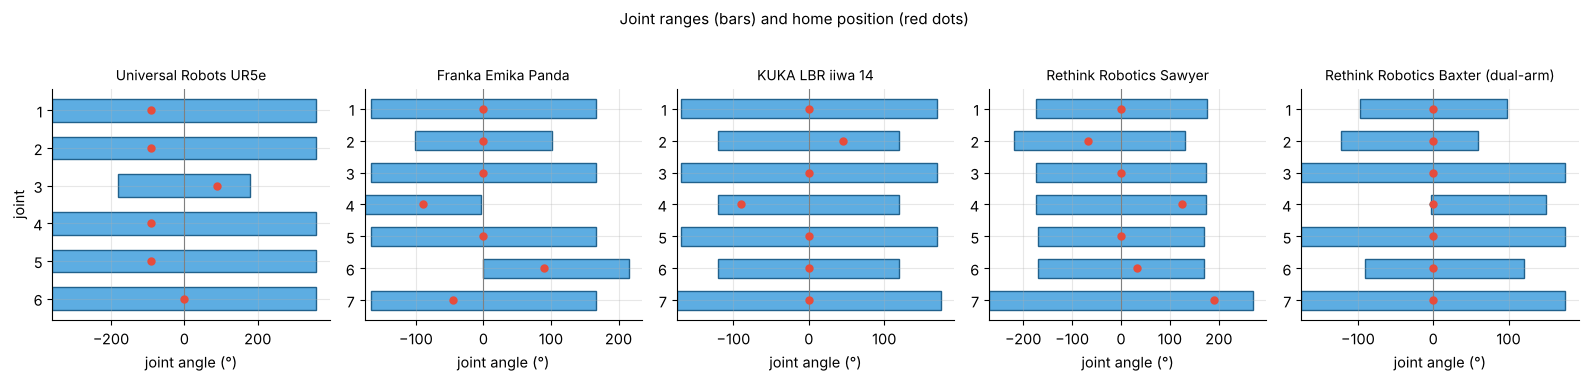

In [11]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.7))
for ax, name in zip(axs, ["ur5e", "panda", "iiwa14", "sawyer", "baxter"]):
    m, d = models[name]
    rows = chains[name]
    for k, r in enumerate(rows):
        lo_, hi_ = np.degrees(r["range"])
        ax.barh(k, hi_ - lo_, left=lo_, color="#5dade2", ec="#21618c", height=0.6)
        q0 = np.degrees(m.key_qpos[0][r["qposadr"]]) if m.nkey else 0.0
        ax.plot(q0, k, "o", color="#e74c3c", ms=5, zorder=5)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([f"{k}" for k in range(1, len(rows) + 1)]); ax.invert_yaxis()
    ax.axvline(0, color="grey", lw=0.8); ax.set_xlabel("joint angle (°)"); ax.set_title(robots.ROBOTS[name]["title"], fontsize=10)
axs[0].set_ylabel("joint")
fig.suptitle("Joint ranges (bars) and home position (red dots)", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

## 7. A humanoid is a tree

The OP3 is not a chain but a **tree**: the torso (`body_link`, whose pose is the free joint) carries five serial
limbs. The census below walks from the world to the end link of each limb and prints the joint sequence.

In [12]:
mO, dO = models["op3"]; mujoco.mj_forward(mO, dO)
limbs = {"head": "head_tilt_link", "left arm": "l_el_link", "right arm": "r_el_link", "left leg": "l_ank_roll_link", "right leg": "r_ank_roll_link"}
op3_chain = {}
lines = ["| limb | joints (from the torso outwards) | sequence |", "|:--|:--|:-:|"]
for limb, body in limbs.items():
    rows = [r for r in jc.chain_joints(mO, dO, body) if r["type"] != "free"]
    op3_chain[limb] = rows
    lines.append(f"| {limb} | {', '.join('`' + r['name'] + '`' for r in rows)} | **{''.join(r['symbol'] for r in rows)}** |")
display(Markdown("\n".join(lines)))
n_limb = sum(len(v) for v in op3_chain.values())
print(f"joints in the five limbs: {n_limb};  plus the floating base (6) = {n_limb + 6} = nv = {mO.nv}")
assert n_limb + 6 == mO.nv

| limb | joints (from the torso outwards) | sequence |
|:--|:--|:-:|
| head | `head_pan`, `head_tilt` | **RR** |
| left arm | `l_sho_pitch`, `l_sho_roll`, `l_el` | **RRR** |
| right arm | `r_sho_pitch`, `r_sho_roll`, `r_el` | **RRR** |
| left leg | `l_hip_yaw`, `l_hip_roll`, `l_hip_pitch`, `l_knee`, `l_ank_pitch`, `l_ank_roll` | **RRRRRR** |
| right leg | `r_hip_yaw`, `r_hip_roll`, `r_hip_pitch`, `r_knee`, `r_ank_pitch`, `r_ank_roll` | **RRRRRR** |

joints in the five limbs: 20;  plus the floating base (6) = 26 = nv = 26


Each leg is a 6R serial chain, and the names of its joints suggest a structure: *hip yaw, hip roll, hip pitch*, then *knee
pitch*, then *ankle pitch, ankle roll*. A human leg has the same layout — a ball-and-socket hip, a hinge knee and a
two-axis ankle. Do the axes of the OP3's hip really meet at a point? We apply the concurrency test of Section 4 to the
three hip joints, and to the two ankle joints. (The published model rounds one offset: the pitch axis passes $0.1$ mm
from the point where the yaw and roll axes meet, so we accept a miss distance below $0.1$ mm.)

In [13]:
def worst_miss_rows(rows_fn, trials=40):
    worst = 0.0
    for _ in range(trials):
        dO.qpos[:] = random_q(mO); dO.qpos[:7] = mO.qpos0[:7]; mujoco.mj_forward(mO, dO)
        sel = rows_fn(jc.chain_joints(mO, dO, "l_ank_roll_link"))
        worst = max(worst, closest_point_and_miss([(r["anchor"], r["axis"]) for r in sel])[1])
    dO.qpos[:] = mO.qpos0; mujoco.mj_forward(mO, dO)
    return worst

legs = lambda rows: [r for r in rows if r["type"] != "free"]
hip = worst_miss_rows(lambda rows: legs(rows)[:3]); ankle = worst_miss_rows(lambda rows: legs(rows)[-2:])
tol_model = 1e-4                                   # the published model rounds some offsets to 0.1 mm
print(f"hip yaw/roll/pitch axes: worst miss {hip * 1000:.3f} mm  ->  {'concurrent (a spherical hip) within the 0.1 mm rounding of the model' if hip < tol_model else 'not concurrent'}")
print(f"ankle pitch/roll axes:   worst miss {ankle * 1000:.3f} mm  ->  {'intersecting (a universal ankle)' if ankle < tol_model else 'not intersecting'}")
assert hip < tol_model and ankle < 1e-9
lr = legs(jc.chain_joints(mO, dO, "l_ank_roll_link"))
print("hip-to-knee link length  a =", round(jc.axis_relation(lr[2]["anchor"], lr[2]["axis"], lr[3]["anchor"], lr[3]["axis"])[0], 4), "m (hip pitch axis to knee axis)")
print("knee-to-ankle link length a =", round(jc.axis_relation(lr[3]["anchor"], lr[3]["axis"], lr[4]["anchor"], lr[4]["axis"])[0], 4), "m")

hip yaw/roll/pitch axes: worst miss 0.050 mm  ->  concurrent (a spherical hip) within the 0.1 mm rounding of the model
ankle pitch/roll axes:   worst miss 0.000 mm  ->  intersecting (a universal ankle)
hip-to-knee link length  a = 0.1101 m (hip pitch axis to knee axis)
knee-to-ankle link length a = 0.11 m


The OP3's leg is therefore a **spherical hip (three concurrent R joints) – revolute knee – universal ankle (two intersecting R joints)**
chain, the 3-1-2 structure of a human leg; and the thigh and shank lengths are the two non-zero $a$'s between
parallel pitch axes. It is not an accident: a spherical hip and an ankle whose axes meet make the inverse kinematics of
a leg solvable in closed form, which is how humanoid robots place their feet.

An interactive way to see a robot's range of motion is to move all its joints at once from one end of their limits to the other. The explorer renders the
chosen robot with every limited joint at the fraction $t$ of its range.

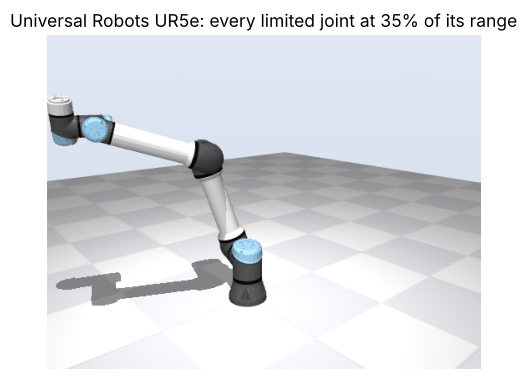

In [14]:
def show_pose(robot="ur5e", t=0.35):
    m, d = models[robot]
    q = m.qpos0.copy()
    for j in range(m.njnt):
        if m.jnt_type[j] in (2, 3) and m.jnt_limited[j]:
            lo_, hi_ = m.jnt_range[j]; q[m.jnt_qposadr[j]] = lo_ + t * (hi_ - lo_)
    d.qpos[:] = q; mujoco.mj_forward(m, d)
    plt.figure(figsize=(5.6, 4.4)); plt.imshow(mju.render(m, d, camera=cams[robot], width=520, height=400)); plt.axis("off")
    plt.title(f"{robots.ROBOTS[robot]['title']}: every limited joint at {t:.0%} of its range"); plt.show()
    d.qpos[:] = m.key_qpos[0] if m.nkey else m.qpos0; mujoco.mj_forward(m, d)

interact(show_pose, robot=widgets.Dropdown(options=["2r", "ur5e", "panda", "iiwa14", "sawyer", "baxter"], value="ur5e", description="robot"),
         t=widgets.FloatSlider(0.35, min=0, max=1, step=0.05, description="range t"));

## 8. Worked examples

**Example 1.2.1 (reading a joint).** From the UR5e table of Section 2, state the type, axis and range of the **elbow**
joint, and the number of independent motions it allows.

*Solution.* The elbow (`elbow_joint`, joint 3) is a hinge ($f=1$): at the home pose it rotates about the horizontal world axis
$(-1, 0, 0)$ and is limited to $\pm 180^\circ$; it is one of three parallel horizontal axes (joints 2, 3, 4).

**Example 1.2.2 (link lengths and reach).** Read the two long link lengths of the UR5e from the model and state the
distance from the shoulder axis to the first wrist axis when the arm is stretched out in a plane.

*Solution.* $a_2 = 0.425$ m and $a_3 = 0.392$ m (Section 3). The three parallel axes (shoulder, elbow, wrist 1) lie in
one plane; with the arm straight the distance from the shoulder axis to the wrist-1 axis is $a_2 + a_3 = 0.817$ m.

**Example 1.2.3 (Panda freedoms).** How many degrees of freedom does the Panda model have, and why is it not `nv` = 9?

*Solution.* The model declares 9 joints (7 arm + 2 fingers) so $n_v = 9$. An equality constraint makes
the two fingers move together: rank 1. Mobility $= 9 - 1 = 8$, equal to the 8 actuators (7 arm joints + 1 gripper).

**Example 1.2.4 (floating-base humanoid).** Verify $n_v = 26$ for the OP3 and state how many velocity numbers each
joint type contributes.

*Solution.* A free joint contributes 6, each of the 20 hinges 1: $6 + 20 = 26$. Quaternion orientation makes
`qpos` have $7 + 20 = 27$ entries, so $n_q - n_v = 1$.

**Example 1.2.5 (which robot has a spherical wrist?).** Using the concurrency test, decide which of the four serial arms of the tour
has a spherical wrist and which a spherical shoulder.

*Solution.* Only the **iiwa 14** has both (miss distance $0$); the **Panda** has a spherical shoulder only (its wrist axes miss by the
$0.088$ m offset) and the **UR5e**, **Sawyer** and **Baxter** have neither.

**Example 1.2.6 (axis classification).** Classify the first three joints of the UR5e and the iiwa 14 by the classical
geometries of Notebook 1.1.

*Solution.* UR5e: R, R, R with axis 1 perpendicular to axis 2 and axis 2 parallel to axis 3 — **articulated (anthropomorphic)**.
iiwa 14: R, R, R with *all three axes concurrent* (a spherical shoulder) — also RRR, but the shoulder is a ball joint built from three revolutes, not a
shoulder–elbow pair with parallel axes; it is not one of the five classical geometries without further qualification.

In [15]:
mU, dU = models["ur5e"]; mujoco.mj_forward(mU, dU)
rows = jc.joint_table(mU, dU)
el = rows[2]
print("1.2.1  elbow:", el["name"], el["type"], "axis", el["axis"].round(2), "range", np.degrees(el["range"]).round(0))
assert el["type"] == "hinge" and np.allclose(el["axis"], [-1, 0, 0], atol=1e-3) and np.allclose(np.degrees(el["range"]), [-180, 180], atol=1e-2)
assert np.allclose(rows[1]["axis"], el["axis"], atol=1e-3) and np.allclose(rows[3]["axis"], el["axis"], atol=1e-3)      # joints 2, 3, 4 parallel

tab = link_table("ur5e")
a2, a3 = tab[1][0], tab[2][0]
print(f"1.2.2  a2 = {a2:.4f} m, a3 = {a3:.4f} m, stretched distance shoulder-axis to wrist-1 axis = {a2 + a3:.4f} m")
assert abs(a2 + a3 - 0.817) < 1e-6

print("1.2.3  Panda: nv =", mP.nv, ", equality rank =", jc.equality_rank(mP, dP), ", mobility =", jc.model_mobility(mP, dP), ", nu =", mP.nu)
assert jc.model_mobility(mP, dP) == 8 == mP.nu
print("1.2.4  OP3: nv =", mO.nv, "= 6 +", mO.nv - 6, "| nq =", mO.nq, "| nq - nv =", mO.nq - mO.nv)
assert mO.nv == 26 == 6 + 20 and mO.nq == 27
print("1.2.5  spherical (shoulder, wrist):", {k: v for k, v in verdict.items()})

1.2.1  elbow: elbow_joint hinge axis [-1.  0.  0.] range [-180.  180.]
1.2.2  a2 = 0.4250 m, a3 = 0.3920 m, stretched distance shoulder-axis to wrist-1 axis = 0.8170 m
1.2.3  Panda: nv = 9 , equality rank = 1 , mobility = 8 , nu = 8
1.2.4  OP3: nv = 26 = 6 + 20 | nq = 27 | nq - nv = 1
1.2.5  spherical (shoulder, wrist): {'ur5e': (np.False_, np.False_), 'panda': (np.True_, np.False_), 'iiwa14': (np.True_, np.True_), 'sawyer': (np.False_, np.False_), 'baxter': (np.False_, np.False_)}


## 9. Summary

| Idea | Result |
|:--|:--|
| Joint census | `joint_table` gives type, axis, anchor and range of every joint of a MuJoCo model |
| Naming | UR5e **6R**; Panda, iiwa 14, Sawyer and each Baxter arm **7R**; Dynamixel 2R **2R** (planar); OP3 a **tree** of five serial limbs plus a floating base |
| Link length and twist | $a$ = distance, $\alpha$ = angle between consecutive axes; constants of the link; they become D-H parameters |
| Spherical shoulder / wrist | three axes concurrent in *every* configuration; iiwa: both; Panda: shoulder; UR5e, Sawyer, Baxter: neither |
| `nq`, `nv`, `nu` | quaternions make `nq > nv`; equality constraints make mobility $< n_v$; a floating base makes $n_u < n_v$ |
| Humanoid leg | spherical hip – knee – universal ankle (3-1-2), a tree of serial limbs |

### Common mistakes

* Reading the DOF of a robot from `nq`; use `nv` and subtract the rank of the equality constraints.
* Judging a spherical wrist from **one** configuration. Three axes can meet accidentally; test many configurations.
* Assuming the manufacturer's zero configuration is the textbook's: the UR5e's all-zero pose is not the 'home' pose, and the Dynamixel 2R hangs down at zero.
* Confusing the **order of joints in a MuJoCo model** with the kinematic chain: they coincide for serial arms but not for trees (a humanoid has five chains).

## Exercises

**1.2.1** Which joint of the Sawyer has the widest range, and which the narrowest? Give the values in degrees.

<details><summary>Answer</summary>

Joint 7 (`right_j6`) is the widest, $\pm 270^\circ$ (540° in total); the narrowest is joint 5 (`right_j4`), $\pm 171^\circ$ (341° in total); the
other joints lie between 349° and 350°. The code check below prints these numbers.
</details>

**1.2.2** Why does the OP3 have `nq = 27` but `nv = 26`? What would `nq` and `nv` be if the base were welded to the ground?

<details><summary>Answer</summary>

The free joint stores a position (3) and a unit quaternion (4) but moves with 6 velocities. Welded to the ground the base
joint disappears: $n_q = n_v = 20$.
</details>

**1.2.3** For the iiwa 14, find the distance and angle between the axes of joints 3 and 4, and interpret.

<details><summary>Answer</summary>

$a = 0$ and $\alpha = 90^\circ$: the axes are perpendicular and intersecting (code check below).
</details>

**1.2.4** The Panda has 9 declared joints but 8 actuators. Explain, and state what the equality constraint removes.

<details><summary>Answer</summary>

The two finger joints are constrained to be equal; one actuator opens and closes both. The constraint removes one freedom, so
mobility $= 9 - 1 = 8$.
</details>

**1.2.5** (*programming*) Write a function that, given a MuJoCo model and a tip body, returns the string of joint symbols (such as `RRRRRR`)
and the angle between axes 1 and 2. Apply it to the Sawyer.

<details><summary>Answer</summary>

`"".join(r["symbol"] for r in jc.chain_joints(m, d, "right_l6"))` returns `RRRRRRR`; axes 1 and 2 are at $90^\circ$ (with a $0.081$ m offset).
</details>

**1.2.6** For the OP3, the left leg is a 6R chain. How many of its joints belong to the spherical hip, and where is the universal ankle?

<details><summary>Answer</summary>

The first three joints (yaw, roll, pitch) form the hip; the last two (ankle pitch, ankle roll) form the ankle; the fourth joint is the knee.
</details>

In [16]:
# --- verification of the exercise answers ---
mS, dS = models["sawyer"]; mujoco.mj_forward(mS, dS)
rS = jc.chain_joints(mS, dS, "right_l6")
widths = [(r["name"], np.degrees(r["range"][1] - r["range"][0]), np.degrees(r["range"])) for r in rS]
widest, narrowest = max(widths, key=lambda w: w[1]), min(widths, key=lambda w: w[1])
print("1.2.1  widest:", widest[0], round(widest[1]), "deg", widest[2].round(0), "| narrowest:", narrowest[0], round(narrowest[1]), "deg", narrowest[2].round(0))
print("1.2.1  all widths:", [round(w[1]) for w in widths])

print("1.2.2  welded base: nq = nv =", mO.nq - 7, "(the 20 hinges)")
mI, dI = models["iiwa14"]; mujoco.mj_forward(mI, dI)
rI = jc.chain_joints(mI, dI, "link7")
a, ang = jc.axis_relation(rI[2]["anchor"], rI[2]["axis"], rI[3]["anchor"], rI[3]["axis"])
print(f"1.2.3  iiwa joints 3-4: a = {a:.1e} m, alpha = {np.degrees(ang):.0f} deg ->", jc.axis_kind(a, ang)); assert a < 1e-9 and abs(np.degrees(ang) - 90) < 1e-6
print("1.2.4  Panda: declared", mP.njnt, "- rank", jc.equality_rank(mP, dP), "=", jc.model_mobility(mP, dP), "= nu =", mP.nu)
print("1.2.5  Sawyer:", "".join(r["symbol"] for r in rS), "| angle axes 1-2:", round(np.degrees(jc.axis_relation(rS[0]["anchor"], rS[0]["axis"], rS[1]["anchor"], rS[1]["axis"])[1])),
      "deg | offset a =", round(jc.axis_relation(rS[0]["anchor"], rS[0]["axis"], rS[1]["anchor"], rS[1]["axis"])[0], 3), "m")
print("1.2.6  left-leg joints:", [r["name"] for r in op3_chain["left leg"]])

1.2.1  widest: right_j6 540 deg [-270.  270.] | narrowest: right_j4 341 deg [-171.  171.]
1.2.1  all widths: [350, 349, 349, 349, 341, 341, 540]
1.2.2  welded base: nq = nv = 20 (the 20 hinges)
1.2.3  iiwa joints 3-4: a = 1.4e-16 m, alpha = 90 deg -> perpendicular, intersecting
1.2.4  Panda: declared 9 - rank 1 = 8 = nu = 8
1.2.5  Sawyer: RRRRRRR | angle axes 1-2: 90 deg | offset a = 0.081 m
1.2.6  left-leg joints: ['l_hip_yaw', 'l_hip_roll', 'l_hip_pitch', 'l_knee', 'l_ank_pitch', 'l_ank_roll']


## Further reading and lectures

* Siciliano et al., Ch. 1 and Spong et al., Ch. 1 for the classical arm and wrist structures; Craig, Ch. 1 and the worked
  kinematic examples of Ch. 3.
* Video: [Prof. G. C. Nandi — Lecture 1 — Introduction](https://www.youtube.com/watch?v=7_EEBOgdGM8); [Prof. G. C. Nandi — Lecture 3 — Simple concepts of forward and inverse kinematics](https://www.youtube.com/watch?v=2ww-3c08BIs).
* MuJoCo Menagerie, the source of all six models: <https://github.com/google-deepmind/mujoco_menagerie>.
* Planned next (not yet written): a notebook on Grübler's formula and degrees of freedom of closed chains, then configuration space and workspace.

---

[← 1.1 Robots, Links and Joints](1.1-robots-links-and-joints.ipynb) &nbsp;·&nbsp; [Chapter contents](README.md) &nbsp;·&nbsp; [1.3 Degrees of Freedom and Grübler's Formula →](1.3-degrees-of-freedom-and-grublers-formula.ipynb)